# 05 · Hiperparámetros y visualización de resultados

Este notebook **no entrena nada**. Reúne y analiza los resultados de los entrenamientos de `01_entrenamiento`:

1. **Búsqueda de hiperparámetros:** tabla comparativa (`results/grid_hiperparametros.csv`) de los 6 entrenamientos: 3 configuraciones × 2 versiones del dataset.
2. **Curvas de entrenamiento:** convergencia de cada modelo.
3. **Predicciones y matriz de confusión** en el conjunto de test.
4. **Histogramas de errores:** calidad de las máscaras y error de profundidad Z en la prueba real.

**Qué hace falta para ejecutarlo:**
- **Siempre:** los CSV y JSON de `results/`, que están en el repositorio. Alcanzan para las secciones 1, 2 y 4.
- **Solo para recalcular la sección 3:** el dataset en `datasets/laboro_tomato.zip` (ver `data/README.md`) y los pesos en `runs/clase_tomate/*/weights/best.pt`. Si faltan, se usa el resultado guardado en `results/matriz_confusion_test.csv`.

In [1]:
import json
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = RAIZ / "results"
ENT = RES / "entrenamiento"
FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

MODELOS = ["modelo1_yolo11s_lr0.002", "modelo2_yolo11s_lr0.0005", "modelo3_yolo11m_lr0.0005"]
CORTO = {MODELOS[0]: "M1 · s · lr 0,002", MODELOS[1]: "M2 · s · lr 0,0005", MODELOS[2]: "M3 · m · lr 0,0005"}
VERSIONES = {"v1": "v1 · solo maduros", "v2": "v2 · maduro + semimaduro"}
COLOR = {MODELOS[0]: "#d6453a", MODELOS[1]: "#f0a030", MODELOS[2]: "#3c7dd9"}
print("resultados en", RES)

resultados en C:\Users\gatog\OneDrive\Escritorio\FIUNA\9no semestre\IA\Trabajo Practico\Tomates3D\results


## 1. Búsqueda de hiperparámetros

### Parámetros vs. hiperparámetros
- **Parámetros:** los pesos de la red, 10,08 M en yolo11s y 22,36 M en yolo11m. Los ajusta **automáticamente** el optimizador durante el entrenamiento.
- **Hiperparámetros:** los valores que se eligen **antes** de entrenar: learning rate, tamaño del modelo, épocas, batch, aumentos, definición de las clases.

### El optimizador: AdamW
Los pesos se ajustan con **AdamW** (Adam con *weight decay* desacoplado). Para cada peso, Adam mantiene una media móvil del gradiente (momento, 0,937) y de su cuadrado, y adapta el tamaño del paso: los pesos con gradientes grandes y ruidosos avanzan más despacio. Converge rápido con pocos datos y es el optimizador que Ultralytics elige automáticamente para datasets chicos. Configuración usada en los 6 entrenamientos:

| Hiperparámetro del optimizador | Valor |
|---|---|
| lr0 (learning rate inicial) | 0,002 o 0,0005 (lo que se compara) |
| Warm-up | 3 épocas (el LR sube gradualmente para no dañar los pesos preentrenados) |
| Decaimiento | lineal hasta lr0 · 0,01 en la época 100 |
| Weight decay | 0,0005 (regularización L2 desacoplada) |
| Épocas / batch / imagen | 100 / 16 / 640 px, con paciencia de 25 épocas |

### Por qué la búsqueda fue manual y no con Optuna o Grid Search automático
El objetivo era **entender el efecto de cada decisión**, no solo encontrar el mejor número. Por eso se cambió **una variable por vez** y a mano:
1. **Learning rate** (M1 → M2): mismo modelo, LR 4 veces menor.
2. **Tamaño del modelo** (M2 → M3): el mejor LR, elegido **en validación**, con un modelo más grande.
3. **Definición de la clase** (v1 → v2): solo maduros frente a maduros + semimaduros.

Además, **cada entrenamiento cuesta entre 0,5 y 0,9 h de GPU** en Colab. Un estudio con Optuna necesita decenas de entrenamientos y no entraba en el tiempo de GPU disponible. La búsqueda manual dirigida dio 6 corridas interpretables. Es una grilla parcial: la combinación *yolo11m con lr 0,002* no se probó.

In [2]:
filas = []
for m in MODELOS:
    for v in VERSIONES:
        d = ENT / f"{m}_{v}"
        val = json.loads((d / "metricas_val.json").read_text())
        test = json.loads((d / "metricas_test.json").read_text())
        fin = json.loads((d / "terminado.json").read_text())
        filas.append({
            "modelo": CORTO[m], "arquitectura": test["arquitectura"], "lr0": test["lr0"], "version_dataset": v,
            "val_mAP50-95_mascara": val["mAP50-95_mascara"],
            "test_precision": test["precision_mascara"], "test_recall": test["recall_mascara"],
            "test_f1": test["f1_mascara"], "test_mAP50": test["mAP50_mascara"],
            "test_mAP50-95_mascara": test["mAP50-95_mascara"], "test_mAP50-95_caja": test["mAP50-95_caja"],
            "ms_por_imagen_T4": test["ms_por_imagen"], "parametros_M": test["parametros_M"],
            "mejor_epoca": test["mejor_epoca"], "horas_entrenamiento": fin["horas_entrenamiento"],
        })
grid = pd.DataFrame(filas)
grid.to_csv(RES / "grid_hiperparametros.csv", index=False)
print("Guardado:", RES / "grid_hiperparametros.csv")
display(grid.style.format(precision=3).highlight_max(
    subset=["val_mAP50-95_mascara", "test_recall", "test_f1", "test_mAP50-95_mascara"], color="#c8f0c8"))

Guardado: C:\Users\gatog\OneDrive\Escritorio\FIUNA\9no semestre\IA\Trabajo Practico\Tomates3D\results\grid_hiperparametros.csv


,modelo,arquitectura,lr0,version_dataset,val_mAP50-95_mascara,test_precision,test_recall,test_f1,test_mAP50,test_mAP50-95_mascara,test_mAP50-95_caja,ms_por_imagen_T4,parametros_M,mejor_epoca,horas_entrenamiento
0,"M1 · s · lr 0,002",yolo11s-seg,0.002,v1,0.790,0.833,0.745,0.787,0.856,0.698,0.750,10.352,10.083,96,0.580
1,"M1 · s · lr 0,002",yolo11s-seg,0.002,v2,0.816,0.919,0.838,0.877,0.924,0.753,0.819,9.994,10.083,76,0.540
2,"M2 · s · lr 0,0005",yolo11s-seg,0.001,v1,0.800,0.816,0.795,0.805,0.865,0.698,0.758,10.535,10.083,75,0.580
3,"M2 · s · lr 0,0005",yolo11s-seg,0.001,v2,0.820,0.916,0.862,0.888,0.921,0.759,0.823,9.454,10.083,57,0.530
4,"M3 · m · lr 0,0005",yolo11m-seg,0.001,v1,0.802,0.816,0.804,0.810,0.862,0.710,0.763,26.238,22.360,79,0.890
5,"M3 · m · lr 0,0005",yolo11m-seg,0.001,v2,0.829,0.913,0.869,0.891,0.934,0.766,0.834,25.670,22.360,80,0.830


**Cómo se eligió cada paso (siempre con validación, nunca con test):**
- **v2:** M1 0,816 vs. M2 0,820 de mAP50-95 de máscara en validación → gana **lr 0,0005**, que se usa en M3.
- **v2:** M3 llega a **0,829** en validación → es el modelo que usa el sistema (`weights/best.pt`).

Las métricas de test de v1 y v2 **no son comparables número a número**, porque cada versión se evalúa con su propia definición de "tomate". La comparación justa entre versiones es la prueba real de la sección 4.

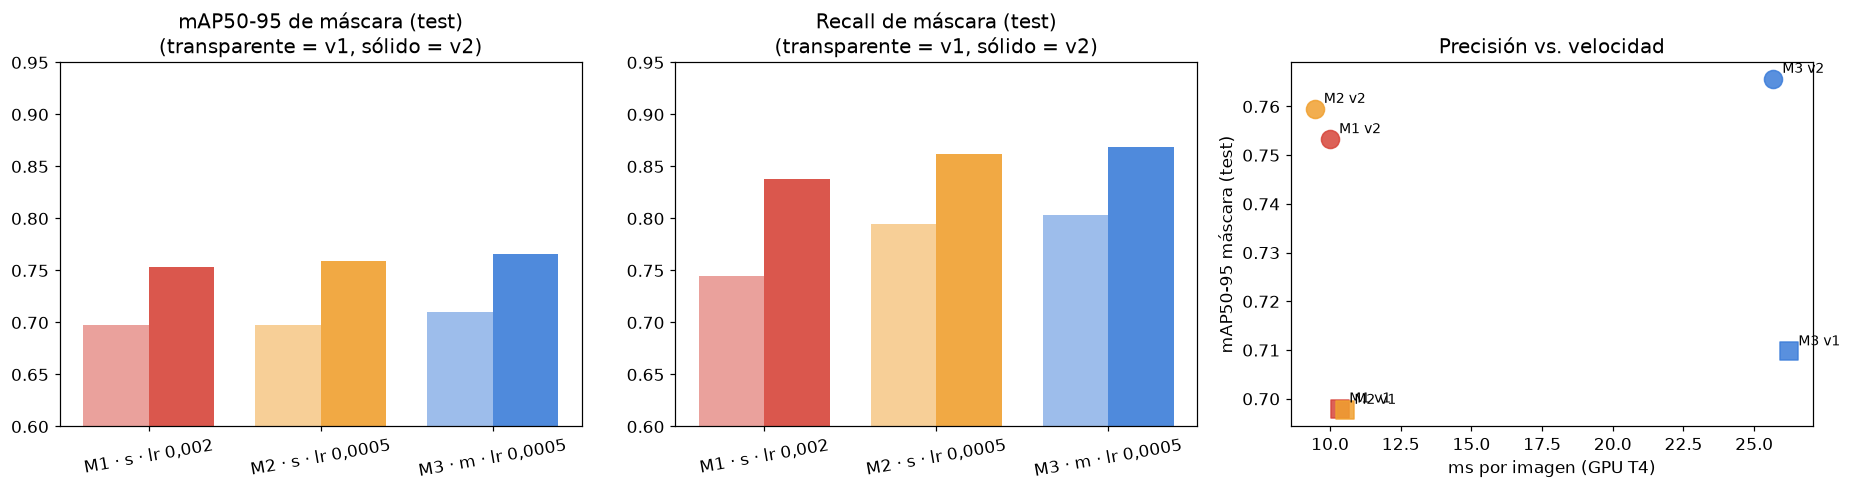

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(len(MODELOS))
for i, (v, tit) in enumerate(VERSIONES.items()):
    sub = grid[grid.version_dataset == v]
    axes[0].bar(x + (i - 0.5) * 0.38, sub["test_mAP50-95_mascara"], 0.38, label=tit, alpha=0.9 if v == "v2" else 0.5,
                color=[COLOR[m] for m in MODELOS])
    axes[1].bar(x + (i - 0.5) * 0.38, sub["test_recall"], 0.38, alpha=0.9 if v == "v2" else 0.5, color=[COLOR[m] for m in MODELOS])
for ax, t in zip(axes[:2], ["mAP50-95 de máscara (test)", "Recall de máscara (test)"]):
    ax.set_xticks(x, [CORTO[m] for m in MODELOS], rotation=10)
    ax.set_ylim(0.6, 0.95)
    ax.set_title(t + "\n(transparente = v1, sólido = v2)")
for _, r in grid.iterrows():
    axes[2].scatter(r["ms_por_imagen_T4"], r["test_mAP50-95_mascara"], s=140,
                    color=COLOR[[m for m in MODELOS if CORTO[m] == r["modelo"]][0]],
                    marker="o" if r["version_dataset"] == "v2" else "s", alpha=0.85)
    axes[2].annotate(f'{r["modelo"].split(" ·")[0]} {r["version_dataset"]}', (r["ms_por_imagen_T4"], r["test_mAP50-95_mascara"]),
                     textcoords="offset points", xytext=(6, 4), fontsize=9)
axes[2].set_xlabel("ms por imagen (GPU T4)")
axes[2].set_ylabel("mAP50-95 máscara (test)")
axes[2].set_title("Precisión vs. velocidad")
plt.tight_layout()
plt.savefig(FIG / "05_grid_hiperparametros.png", dpi=150)
plt.show()

## 2. Curvas de entrenamiento (convergencia)

Los `results.csv` de Ultralytics registran, por época, las pérdidas de entrenamiento y validación y las métricas de validación.

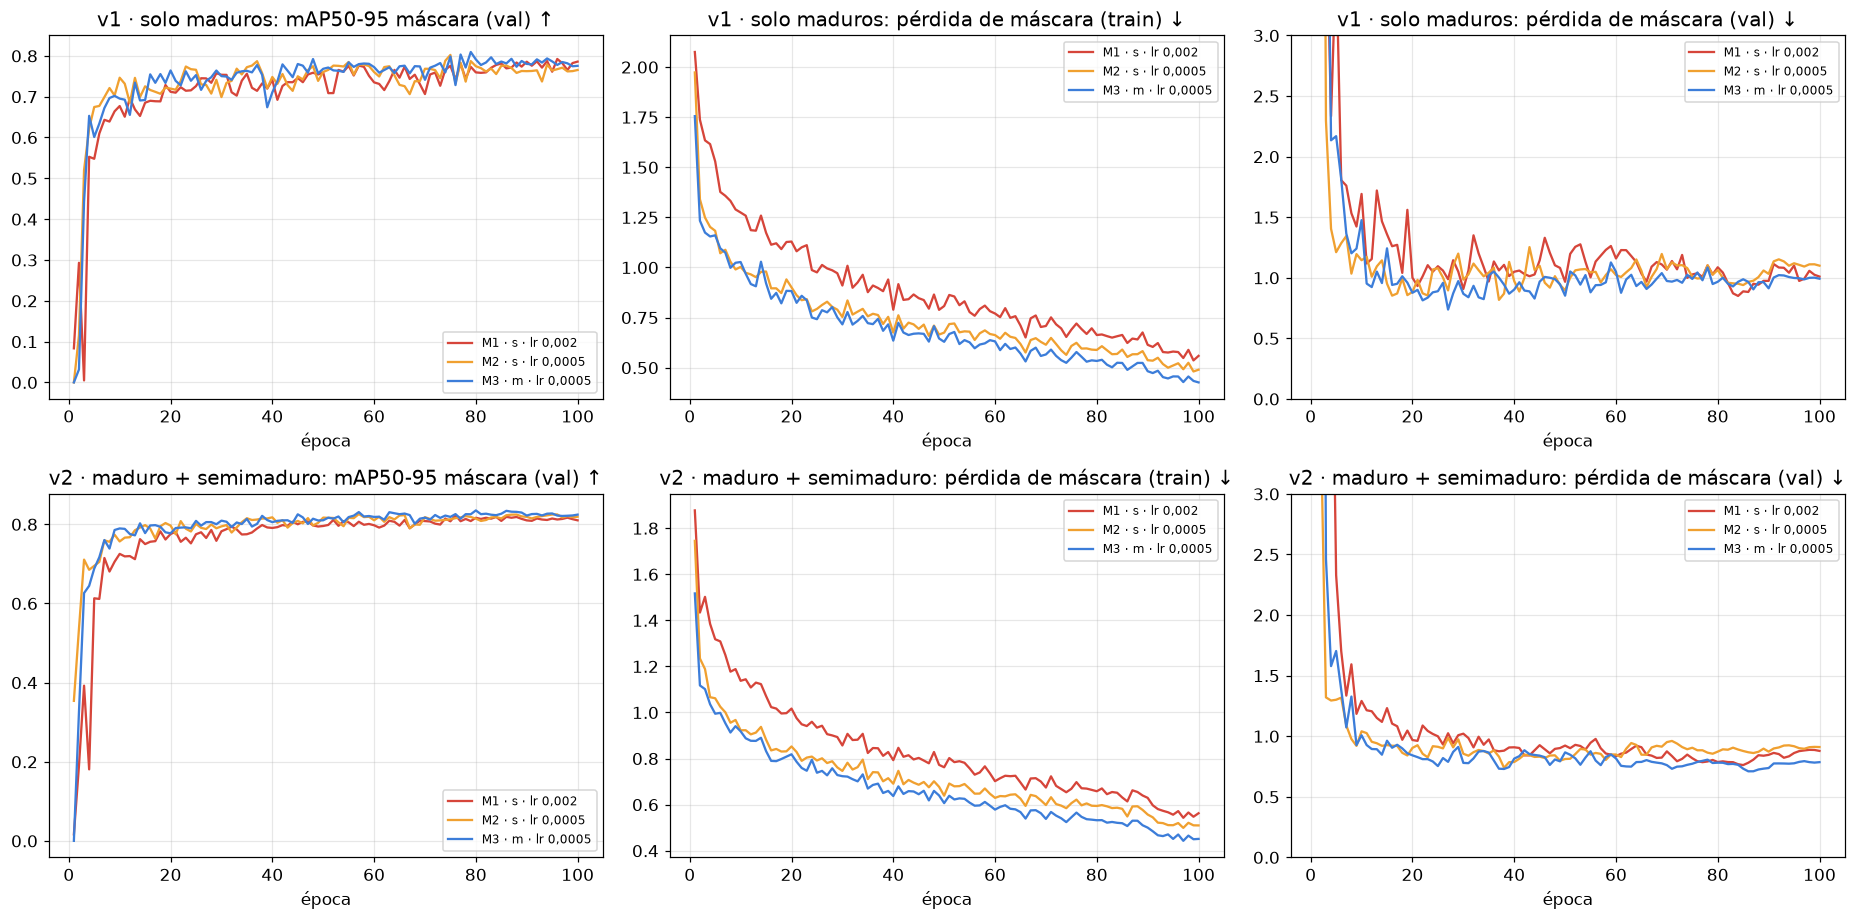

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for fila, v in enumerate(VERSIONES):
    for m in MODELOS:
        df = pd.read_csv(ENT / f"{m}_{v}" / "results.csv")
        df.columns = [c.strip() for c in df.columns]
        axes[fila, 0].plot(df["epoch"], df["metrics/mAP50-95(M)"], label=CORTO[m], color=COLOR[m])
        axes[fila, 1].plot(df["epoch"], df["train/seg_loss"], label=CORTO[m], color=COLOR[m])
        axes[fila, 2].plot(df["epoch"], df["val/seg_loss"], label=CORTO[m], color=COLOR[m])
    axes[fila, 0].set_title(f"{VERSIONES[v]}: mAP50-95 máscara (val) ↑")
    axes[fila, 1].set_title(f"{VERSIONES[v]}: pérdida de máscara (train) ↓")
    axes[fila, 2].set_title(f"{VERSIONES[v]}: pérdida de máscara (val) ↓")
    axes[fila, 2].set_ylim(0, 3)
    for ax in axes[fila]:
        ax.set_xlabel("época")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "05_curvas_entrenamiento.png", dpi=150)
plt.show()

**Lectura:**
- **LR alto = arranque inestable:** con lr 0,002 (M1), el mAP de validación cae en las primeras épocas (época 4 en v2) antes de recuperarse. Con 0,0005, la curva sube de forma monótona desde el inicio.
- **Convergencia:** todos llegan a una meseta cerca de la época 40. Las mejoras posteriores son de milésimas.
- **Sobreajuste leve:** la pérdida de entrenamiento sigue bajando hasta el final mientras la de validación queda plana. Como se guarda la mejor época (best.pt) y la validación no empeora, no afecta al modelo final.
- La escala de la pérdida de validación se recorta en 3: en la primera época hay picos de 50–140 por la cabeza recién inicializada (80 → 1 clase).

## 3. Predicciones y matriz de confusión en test

Se evalúan los 3 modelos v2 sobre las **161 imágenes de test** (680 tomates) con los criterios reales del sistema:
- **Umbral de confianza 0,35**, el mismo que usa la página web.
- **Acierto:** IoU de **máscara** ≥ 0,5 con un tomate anotado, con emparejamiento de a pares por mayor IoU.

En detección no existe la celda "fondo predicho como fondo": serían todas las posiciones sin tomate de todas las imágenes. Por eso la matriz es de 2×2 con una celda vacía y no se calcula accuracy.

Las imágenes se decodifican a 1/4 de su resolución (1008×756), suficiente porque el modelo trabaja a 640 px.

In [5]:
CONF, IOU_ACIERTO = 0.35, 0.5
ZIP = next((p for p in (RAIZ / "datasets" / "laboro_tomato.zip", RAIZ / "data" / "raw" / "laboro_tomato.zip") if p.is_file()), None)
PESOS = {m: RAIZ / "runs" / "clase_tomate" / m / "weights" / "best.pt" for m in MODELOS}
puede_calcular = ZIP is not None and all(p.is_file() for p in PESOS.values())
print("dataset:", ZIP, "| pesos disponibles:", all(p.is_file() for p in PESOS.values()))


def es_tomate(nombre):
    n = nombre.lower()
    return "fully" in n or "half" in n or "semi" in n


def mejor_poligono(ann):
    seg = ann.get("segmentation")
    if isinstance(seg, list) and seg:
        polys = [p for p in seg if isinstance(p, list) and len(p) >= 6]
        if polys:
            area = lambda p: abs(sum(p[0::2][i] * p[1::2][i - 1] - p[0::2][i - 1] * p[1::2][i] for i in range(len(p) // 2))) / 2
            return max(polys, key=area)
    x, y, w, h = ann["bbox"]
    t = np.linspace(0, 2 * np.pi, 32, endpoint=False)
    return np.column_stack([x + w / 2 + w / 2 * np.cos(t), y + h / 2 + h / 2 * np.sin(t)]).ravel().tolist()


def cargar_test(zp):
    z = zipfile.ZipFile(zp)
    indice = {Path(n).name: n for n in z.namelist() if n.lower().endswith(".jpg")}
    coco = json.loads(z.read(next(n for n in z.namelist() if n.endswith("test.json"))))
    cats = {c["id"]: c["name"] for c in coco["categories"]}
    anns = {}
    for a in coco["annotations"]:
        if es_tomate(cats[a["category_id"]]):
            anns.setdefault(a["image_id"], []).append(mejor_poligono(a))
    for im in coco["images"]:
        img = cv2.imdecode(np.frombuffer(z.read(indice[Path(im["file_name"]).name]), np.uint8), cv2.IMREAD_REDUCED_COLOR_4)
        h, w = img.shape[:2]
        sx, sy = w / im["width"], h / im["height"]
        reales = []
        for poly in anns.get(im["id"], []):
            m = np.zeros((h, w), np.uint8)
            cv2.fillPoly(m, [(np.array(poly).reshape(-1, 2) * [sx, sy]).round().astype(np.int32)], 1)
            reales.append(m.astype(bool))
        yield Path(im["file_name"]).name, img, reales


def iou(a, b):
    u = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / u if u else 0.0


def evaluar_modelo(modelo, datos):
    tp = fp = fn = 0
    ious, conf_tp, conf_fp = [], [], []
    for _, img, reales in datos:
        r = modelo.predict(img, imgsz=640, conf=CONF, retina_masks=True, verbose=False)[0]
        preds = [] if r.masks is None else [mk > 0.5 for mk in r.masks.data.cpu().numpy()]
        confs = [] if r.boxes is None else r.boxes.conf.cpu().numpy().tolist()
        cand = sorted(((iou(p, g), i, j) for i, p in enumerate(preds) for j, g in enumerate(reales)), reverse=True)
        up, ug = {}, set()
        for v, i, j in cand:
            if v < IOU_ACIERTO:
                break
            if i not in up and j not in ug:
                up[i] = v
                ug.add(j)
        tp += len(up); fp += len(preds) - len(up); fn += len(reales) - len(ug)
        ious += list(up.values())
        conf_tp += [confs[i] for i in up]
        conf_fp += [c for i, c in enumerate(confs) if i not in up]
    return {"TP": tp, "FP": fp, "FN": fn}, {"iou_tp": ious, "conf_tp": conf_tp, "conf_fp": conf_fp}

dataset: C:\Users\gatog\OneDrive\Escritorio\FIUNA\9no semestre\IA\Trabajo Practico\Tomates3D\datasets\laboro_tomato.zip | pesos disponibles: True


In [6]:
if puede_calcular:
    from ultralytics import YOLO
    datos = list(cargar_test(ZIP))
    print(f"test: {len(datos)} imágenes, {sum(len(r) for _, _, r in datos)} tomates")
    conteos, detalle = {}, {}
    for m in MODELOS:
        conteos[m], detalle[m] = evaluar_modelo(YOLO(str(PESOS[m])), datos)
        print(CORTO[m], conteos[m])
    cm = pd.DataFrame(conteos).T
    cm["precision"] = cm.TP / (cm.TP + cm.FP)
    cm["recall"] = cm.TP / (cm.TP + cm.FN)
    cm["f1"] = 2 * cm.precision * cm.recall / (cm.precision + cm.recall)
    cm.index = [CORTO[m] for m in cm.index]
    cm.to_csv(RES / "matriz_confusion_test.csv")
    (RES / "errores_test_detalle.json").write_text(json.dumps({CORTO[m]: d for m, d in detalle.items()}))
else:
    print("Sin dataset o pesos: se usan los resultados guardados.")
    cm = pd.read_csv(RES / "matriz_confusion_test.csv", index_col=0)
    detalle = {m: d for m, d in json.loads((RES / "errores_test_detalle.json").read_text()).items()}
display(cm.round(3))

test: 161 imágenes, 680 tomates


M1 · s · lr 0,002 {'TP': 601, 'FP': 107, 'FN': 79}


M2 · s · lr 0,0005 {'TP': 618, 'FP': 101, 'FN': 62}


M3 · m · lr 0,0005 {'TP': 613, 'FP': 120, 'FN': 67}


,TP,FP,FN,precision,recall,f1
"M1 · s · lr 0,002",601,107,79,0.849,0.884,0.866
"M2 · s · lr 0,0005",618,101,62,0.860,0.909,0.883
"M3 · m · lr 0,0005",613,120,67,0.836,0.901,0.868


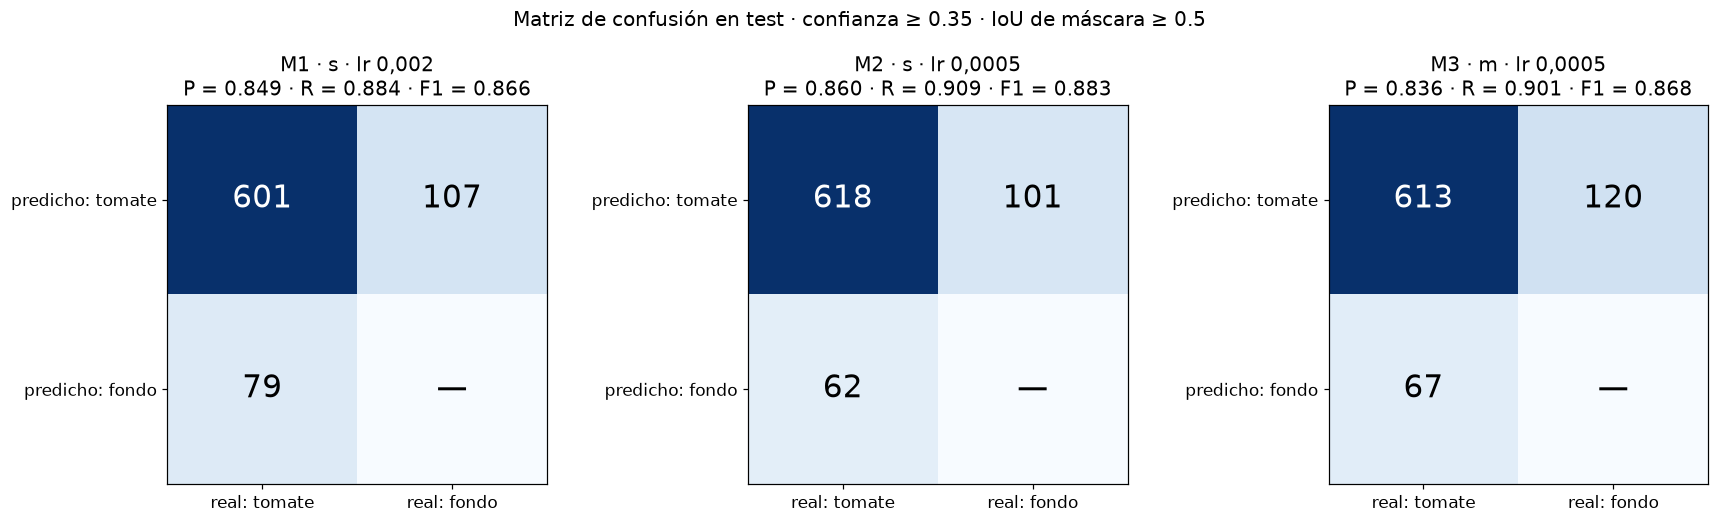

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nombre, c) in zip(axes, cm.iterrows()):
    mat = np.array([[c.TP, c.FP], [c.FN, np.nan]], dtype=float)
    ax.imshow(np.nan_to_num(mat), cmap="Blues", vmin=0, vmax=np.nanmax(mat))
    for (i, j), val in np.ndenumerate(mat):
        ax.text(j, i, "—" if np.isnan(val) else int(val), ha="center", va="center", fontsize=20,
                color="white" if not np.isnan(val) and val > np.nanmax(mat) / 2 else "black")
    ax.set_xticks([0, 1], ["real: tomate", "real: fondo"])
    ax.set_yticks([0, 1], ["predicho: tomate", "predicho: fondo"])
    ax.set_title(f"{nombre}\nP = {c.precision:.3f} · R = {c.recall:.3f} · F1 = {c.f1:.3f}")
fig.suptitle(f"Matriz de confusión en test · confianza ≥ {CONF} · IoU de máscara ≥ {IOU_ACIERTO}")
plt.tight_layout()
plt.savefig(FIG / "05_matriz_confusion_test.png", dpi=150)
plt.show()

P, R y F1 de esta matriz difieren un poco de los de la tabla de Ultralytics. Ultralytics informa P y R en el umbral que maximiza F1 y con su propio emparejamiento; acá se usa el **umbral fijo del sistema (0,35)**.

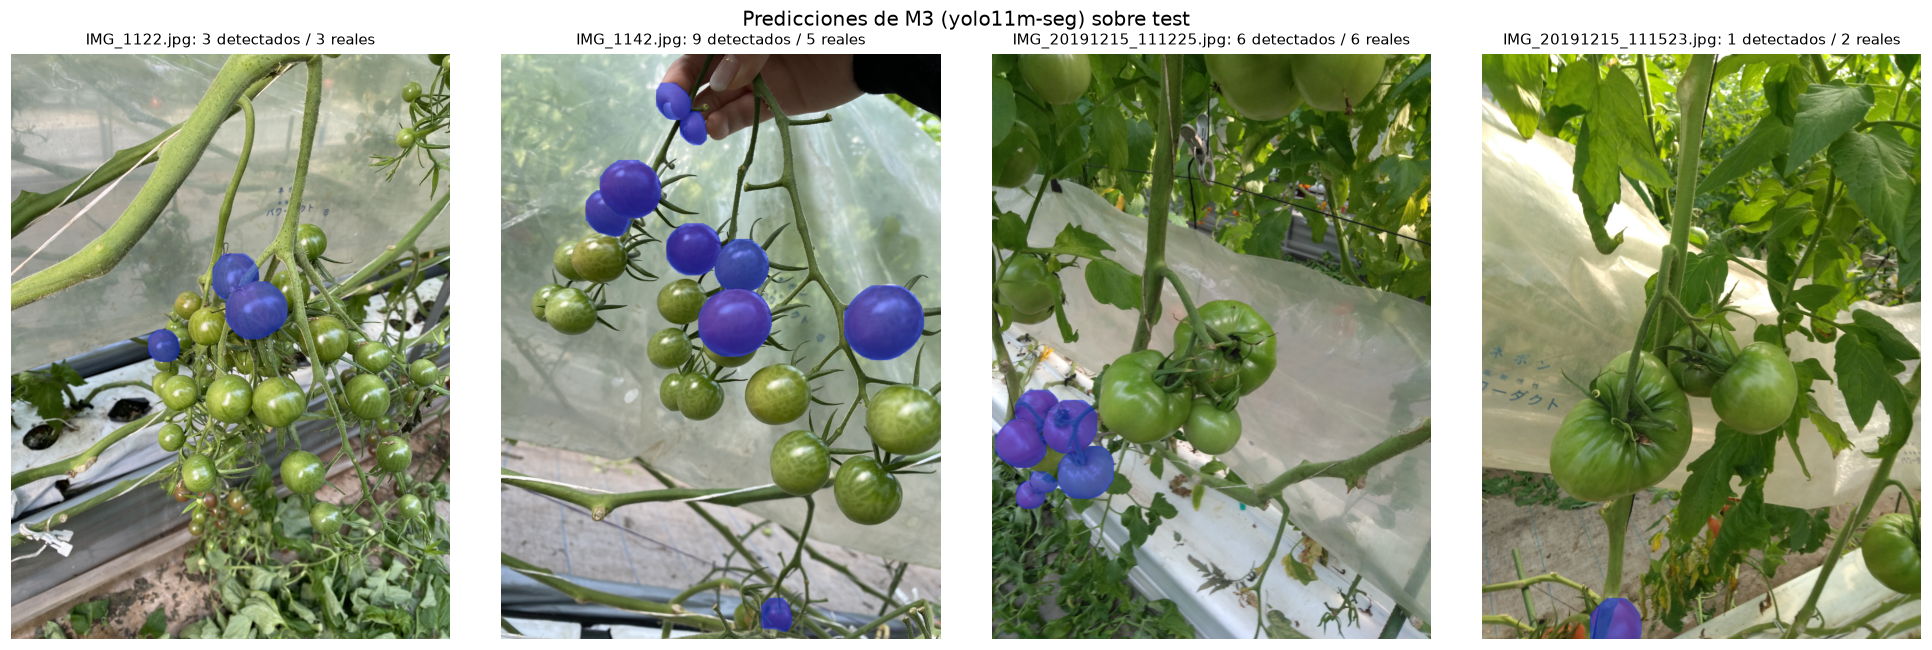

In [8]:
if puede_calcular:
    from ultralytics import YOLO
    m3 = YOLO(str(PESOS[MODELOS[2]]))
    elegidas = [d for d in datos if d[2]][:4]
    fig, axes = plt.subplots(1, 4, figsize=(18, 6))
    for ax, (nombre, img, reales) in zip(axes, elegidas):
        r = m3.predict(img, imgsz=640, conf=CONF, retina_masks=True, verbose=False)[0]
        ax.imshow(r.plot(labels=True, boxes=False)[:, :, ::-1])
        ax.set_title(f"{nombre}: {len(r.boxes)} detectados / {len(reales)} reales", fontsize=10)
        ax.axis("off")
    plt.suptitle("Predicciones de M3 (yolo11m-seg) sobre test")
    plt.tight_layout()
    plt.savefig(FIG / "05_predicciones_test.png", dpi=120)
    plt.show()

## 4. Histogramas de errores

### 4.1 Calidad de las máscaras y confianza (test)
- **IoU de cada tomate bien detectado:** qué tan precisa es la forma de la máscara. Es lo que importa para el centroide y, por lo tanto, para Z.
- **Confianza de aciertos y falsos positivos:** muestra si el umbral 0,35 separa bien ambos grupos.

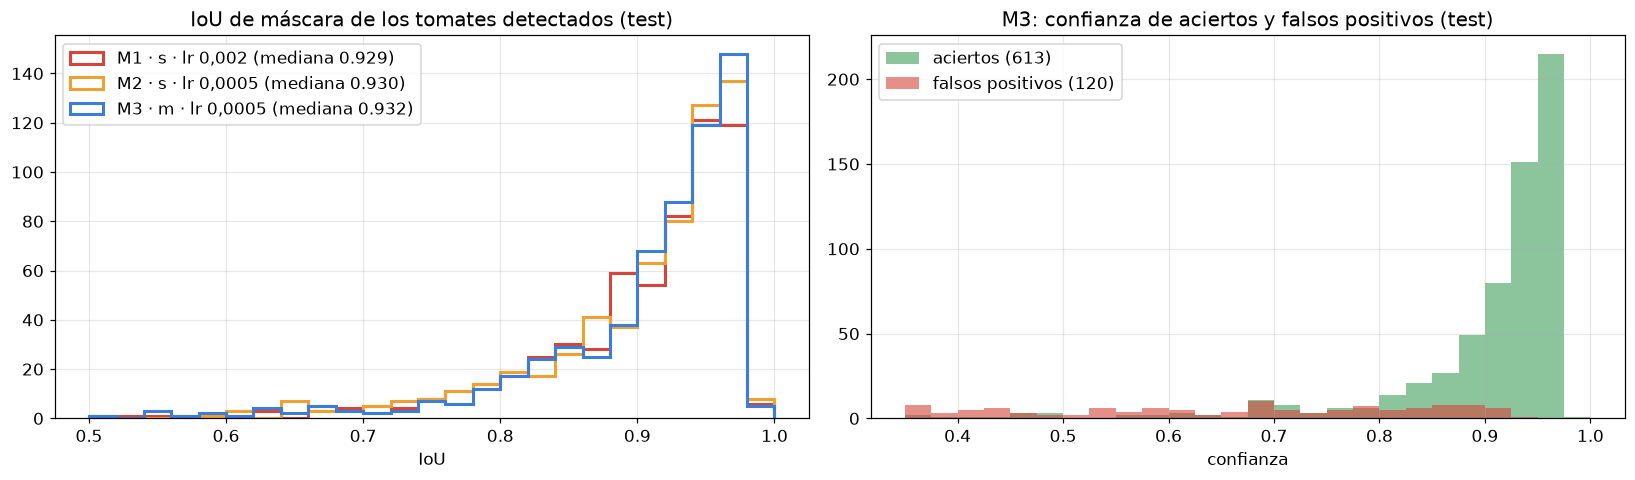

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for m in MODELOS:
    d = detalle[CORTO[m]] if CORTO[m] in detalle else detalle[m]
    axes[0].hist(d["iou_tp"], bins=np.linspace(0.5, 1, 26), histtype="step", lw=2, color=COLOR[m],
                 label=f"{CORTO[m]} (mediana {np.median(d['iou_tp']):.3f})")
d3 = detalle[CORTO[MODELOS[2]]] if CORTO[MODELOS[2]] in detalle else detalle[MODELOS[2]]
axes[1].hist(d3["conf_tp"], bins=np.linspace(0.35, 1, 27), alpha=0.6, color="#3f9e5a", label=f"aciertos ({len(d3['conf_tp'])})")
axes[1].hist(d3["conf_fp"], bins=np.linspace(0.35, 1, 27), alpha=0.6, color="#d6453a", label=f"falsos positivos ({len(d3['conf_fp'])})")
axes[0].set_title("IoU de máscara de los tomates detectados (test)")
axes[0].set_xlabel("IoU")
axes[1].set_title("M3: confianza de aciertos y falsos positivos (test)")
axes[1].set_xlabel("confianza")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "05_hist_iou_confianza.png", dpi=150)
plt.show()

### 4.2 Error de profundidad en la prueba real

10 pares estéreo del tomate sostenido por el brazo a **47 cm** (`data/capturas_reales/`), procesados con los 6 modelos y con el detector OpenCV. El error es Z medida − 47 cm, medida al centro del fruto. También se cuentan los falsos positivos por captura (el respaldo de madera de una silla).

detectado  z_media_cm  error_medio_cm  \
modelo                   version                                          
modelo1_yolo11s_lr0.002  v1             1.0      47.758           0.758   
                         v2             1.0      47.704           0.704   
modelo2_yolo11s_lr0.0005 v1             1.0      47.662           0.662   
                         v2             1.0      47.776           0.776   
modelo3_yolo11m_lr0.0005 v1             1.0      47.721           0.721   
                         v2             1.0      47.769           0.769   

                                  desvio_mm  falsos_pos_por_captura  
modelo                   version                                     
modelo1_yolo11s_lr0.002  v1           0.215                     0.0  
                         v2           0.171                     2.0  
modelo2_yolo11s_lr0.0005 v1           0.239                     0.0  
                         v2           0.288                     1.0  
modelo3_yolo11m_lr0.0005 v1           0.223                     0.0  
                         v2           0.160                     1.0

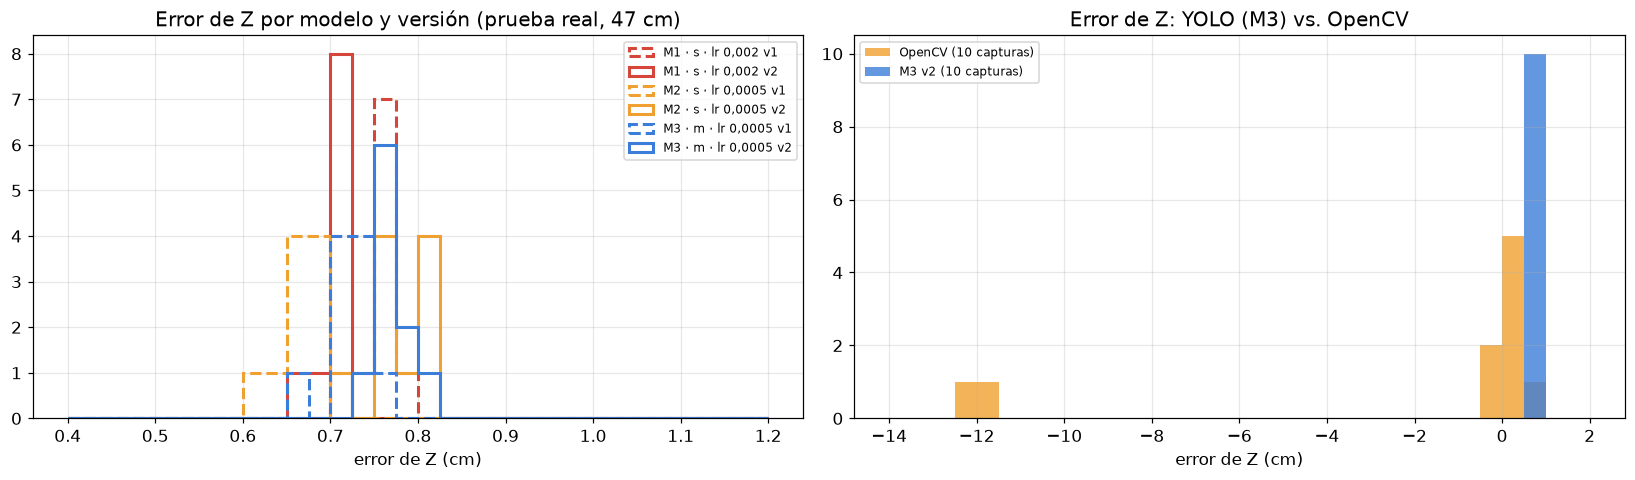

In [10]:
real = pd.read_csv(RES / "prueba_real_versiones.csv")
Z_REAL = 0.47
real["error_cm"] = (real.z_centro_m - Z_REAL) * 100
yolo = real[real.metodo == "yolo"]
resumen_real = yolo.groupby(["modelo", "version"]).agg(
    detectado=("tomate_detectado", "mean"), z_media_cm=("z_centro_m", lambda s: 100 * s.mean()),
    error_medio_cm=("error_cm", "mean"), desvio_mm=("error_cm", lambda s: 10 * s.std()),
    falsos_pos_por_captura=("falsos_positivos", "mean")).round(3)
display(resumen_real)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for (m, v), g in yolo.groupby(["modelo", "version"]):
    axes[0].hist(g.error_cm, bins=np.linspace(0.4, 1.2, 33), histtype="step", lw=2, color=COLOR[m],
                 ls="-" if v == "v2" else "--", label=f"{CORTO[m]} {v}")
ocv = real[real.metodo == "opencv"]
axes[1].hist(ocv.error_cm, bins=np.linspace(-14, 2, 33), color="#f0a030", alpha=0.8, label="OpenCV (10 capturas)")
axes[1].hist(yolo[(yolo.modelo == MODELOS[2]) & (yolo.version == "v2")].error_cm, bins=np.linspace(-14, 2, 33),
             color="#3c7dd9", alpha=0.8, label="M3 v2 (10 capturas)")
axes[0].set_title("Error de Z por modelo y versión (prueba real, 47 cm)")
axes[1].set_title("Error de Z: YOLO (M3) vs. OpenCV")
for ax in axes:
    ax.set_xlabel("error de Z (cm)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "05_hist_error_z.png", dpi=150)
plt.show()

**Lectura:**
- **Las 6 versiones de YOLO** miden el tomate entre 47,7 y 47,8 cm, con una dispersión de décimas de milímetro. El error de +0,7 a +0,8 cm es **sistemático**: el centro óptico está dentro de la cámara, detrás de su cara frontal, y se corrige con un offset fijo. La profundidad no depende del modelo elegido.
- **OpenCV** mide bien en 8 de 10 capturas (~47,1 cm sobre un fragmento del tomate), pero en 2 empareja mal los fragmentos y da ~35 cm (error de −12 cm). El watershed parte el tomate alargado en dos.
- **Falsos positivos:** las versiones v1 no tienen ninguno. Las v2 detectan el respaldo de madera de una silla, a unos 3 m: unir los semimaduros (naranjas) hace aceptar objetos de madera anaranjada. Como todos aparecen a más de 2,9 m, un filtro de rango de trabajo (Z ≤ 1 m) los elimina.